# 🎓 ¿Quién abandonará la universidad? Revisité mi modelo y encontré 3 errores
### Naive Bayes para deserción estudiantil, versión 2: la causa real del escalado, el momento de la predicción y los supuestos del modelo

**Autor:** Cristobal Rojas · **Herramientas:** Python, pandas, scikit-learn, matplotlib

---

## 🎯 Contexto (PACE · Planificar)
Una institución de educación superior pierde a **1 de cada 3 estudiantes** antes de titularse. El equipo de retención (tutorías, apoyo financiero, acompañamiento) tiene capacidad limitada y pregunta:

1. **¿Quién tiene mayor riesgo de desertar?**
2. **¿Cuándo podemos saberlo?** Una alerta solo sirve si llega mientras el estudiante todavía está.
3. **¿A cuántos podemos contactar** y cuántos desertores alcanzaríamos?

**Uso responsable:** el modelo prioriza **apoyo**, nunca sanciones, cobros ni rechazos de matrícula. Los puntajes individuales son confidenciales.

**Dataset:** [Predict students' dropout and academic success — Kaggle](https://www.kaggle.com/datasets/thedevastator/higher-education-predictors-of-student-retention) · 4.424 estudiantes · 34 variables · Realinho et al. (2021), institución pública de Portugal. [DOI 10.5281/zenodo.5777340](https://doi.org/10.5281/zenodo.5777340)

## 🔁 ¿Por qué una versión 2?
La **versión 1** de este proyecto (carpeta `version_original/`) entrenó un `GaussianNB` y obtuvo 84,8 % de exactitud. Al revisarla meses después encontré tres problemas:

| # | Lo que decía la v1 | Lo que encontré |
|---|---|---|
| 1 | "Escalar no cambió nada porque no hay variables con escala extrema; en el ejemplo bancario hubo *underflow*" | El mecanismo real es `var_smoothing`. GaussianNB es casi inmune al escalado salvo por ese detalle |
| 2 | Usar notas del 1er **y 2º** semestre | Muchos desertores ya se habían ido al terminar el 2º semestre: el modelo "detectaba" deserciones consumadas |
| 3 | Tratar todas las columnas como numéricas continuas | Curso, ocupación de los padres, etc. son **códigos**, y varias variables están muy correlacionadas: se rompen supuestos de Naive Bayes |

Además, la v1 hablaba de "84,8 % de **precisión**" cuando ese número es la **exactitud** (*accuracy*); la precisión era 77,1 %.

## 🧭 Hoja de ruta
| # | Etapa | Qué aporta |
|---|---|---|
| 1 | Carga y auditoría | Qué variables son códigos y cuándo se conoce cada una |
| 2 | Reproducir la v1 | Partir del mismo resultado: 84,8 % |
| 3 | **Error 1:** el escalado | Experimento que muestra el mecanismo real |
| 4 | **Error 2:** el momento | Tres momentos de predicción: matrícula, 1er semestre, fin de año |
| 5 | **Error 3:** los supuestos | Naive Bayes mixto, calibración y comparación con regresión logística |
| 6 | Validación honesta | Un split vs. validación cruzada repetida |
| 7 | **Alerta temprana** | A cuántos contactar y cuántos desertores se alcanzan |

In [1]:
# ==== Importaciones ====
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, brier_score_loss)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
SEED = 7
IMG = Path("../images"); IMG.mkdir(parents=True, exist_ok=True)
REP = Path("../reports"); REP.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, VERDE, VIOLETA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#8a8984"
TINTA, TINTA2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8, "legend.frameon": False,
})
PCT = plt.FuncFormatter(lambda x, _: f"{x:.0%}")

def es(x, dec=0):
    """Formato numérico chileno: 1.234,5"""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def guardar(nombre):
    plt.savefig(IMG / f"{nombre}.png", facecolor="white")
    plt.show()

## 1. Carga y auditoría (PACE · Analizar)

In [2]:
df = pd.read_csv("../data/dataset.csv")
print(f"Estudiantes: {es(len(df))} | Columnas: {df.shape[1]} | "
      f"Faltantes: {df.isna().sum().sum()} | Duplicados: {df.duplicated().sum()}")
print("\nResultado final de cada estudiante:")
print(df["Target"].value_counts().rename({"Graduate": "Titulado", "Dropout": "Desertó", "Enrolled": "Sigue matriculado"}))

y = (df["Target"] == "Dropout").astype(int).values
print(f"\nTasa de deserción: {es(y.mean() * 100, 1)} %")

Estudiantes: 4.424 | Columnas: 35 | Faltantes: 0 | Duplicados: 0

Resultado final de cada estudiante:
Target
Titulado             2209
Desertó              1421
Sigue matriculado     794
Name: count, dtype: int64

Tasa de deserción: 32,1 %


**Dos cosas que la v1 no revisó:**

**a) Muchas columnas numéricas son en realidad códigos.** `Course` vale de 1 a 17, pero el curso 12 no es "el doble" del curso 6: es otra carrera. Lo mismo ocurre con la ocupación y escolaridad de los padres, el modo de postulación o la nacionalidad. `GaussianNB` asume que cada columna sigue una campana de Gauss, lo que no tiene sentido para un código.

**b) No todas las variables se conocen en el mismo momento.** Las agrupo según cuándo están disponibles para el equipo de retención:

In [3]:
NOMINALES = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
             "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BINARIAS = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Gender",
            "Scholarship holder", "International"]
NUM_MATRICULA = ["Application order", "Age at enrollment", "Unemployment rate", "Inflation rate", "GDP"]
FINANCIERAS = ["Debtor", "Tuition fees up to date"]

def tasa(aprobadas, inscritas):
    return np.where(inscritas > 0, aprobadas / inscritas, 0)

for sem, k in [("1st", 1), ("2nd", 2)]:
    df[f"tasa_aprobacion_{k}"] = tasa(df[f"Curricular units {sem} sem (approved)"],
                                      df[f"Curricular units {sem} sem (enrolled)"])

def semestre(sem, k):
    return [f"Curricular units {sem} sem (credited)", f"Curricular units {sem} sem (evaluations)",
            f"Curricular units {sem} sem (grade)", f"Curricular units {sem} sem (without evaluations)",
            f"tasa_aprobacion_{k}"]

MOMENTOS = {
    "Matrícula":        (NOMINALES + BINARIAS,               NUM_MATRICULA),
    "Fin 1er semestre": (NOMINALES + BINARIAS + FINANCIERAS, NUM_MATRICULA + semestre("1st", 1)),
    "Fin de año":       (NOMINALES + BINARIAS + FINANCIERAS, NUM_MATRICULA + semestre("1st", 1) + semestre("2nd", 2)),
}
pd.DataFrame({m: [len(c), len(n), len(c) + len(n)] for m, (c, n) in MOMENTOS.items()},
             index=["Categóricas", "Numéricas", "Total"])

,Matrícula,Fin 1er semestre,Fin de año
Categóricas,15,17,17
Numéricas,5,10,15
Total,20,27,32


> **Supuesto:** `Debtor` (deuda) y `Tuition fees up to date` (aranceles al día) describen pagos que se observan **durante** el año, no el día de la matrícula. Por eso las ubico desde el fin del 1er semestre. Si en una institución se conocen al matricular, basta con moverlas.

## 2. Reproducir la versión 1
Mismo tratamiento de la v1: tasas de aprobación de ambos semestres, todas las columnas como numéricas, un solo split 75/25 con `random_state=42`.

In [4]:
crudas = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (enrolled)",
          "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (enrolled)"]
X_v1 = df.drop(columns=crudas + ["Target"])
X_tr, X_te, y_tr, y_te = train_test_split(X_v1, y, test_size=0.25, stratify=y, random_state=42)

gnb_v1 = GaussianNB().fit(X_tr, y_tr)
pred_v1 = gnb_v1.predict(X_te)
v1 = {"Exactitud (accuracy)": accuracy_score(y_te, pred_v1), "Precisión": precision_score(y_te, pred_v1),
      "Recall (sensibilidad)": recall_score(y_te, pred_v1), "F1": f1_score(y_te, pred_v1)}
print("Matriz de confusión [VN, FP, FN, VP]:", confusion_matrix(y_te, pred_v1).ravel())
pd.Series(v1).round(3).to_frame("Versión 1")

Matriz de confusión [VN, FP, FN, VP]: [672  79  89 266]


,Versión 1
Exactitud (accuracy),0.848
Precisión,0.771
Recall (sensibilidad),0.749
F1,0.760


Resultado idéntico al de la v1: **84,8 % de exactitud, 77,1 % de precisión y 74,9 % de recall**. La exactitud es el % de aciertos totales; la **precisión** es el % de alertas que resultan ser desertores reales. Son métricas distintas, y la v1 las mezclaba en las conclusiones.

## 3. Error 1: ¿por qué escalar no cambió nada?
La v1 decía que, en el ejemplo bancario del curso, escalar era indispensable porque `Balance` (hasta 250.000) provocaba *underflow* numérico. **No es así.** GaussianNB estima una media y una varianza por variable y clase; si multiplico una variable por 1.000, su media y su desviación también se multiplican por 1.000 y la probabilidad relativa entre clases no cambia.

El único detalle que rompe esa inmunidad es `var_smoothing`: para evitar varianzas cero, scikit-learn suma a **todas** las varianzas un valor igual a `1e-9 × (la varianza más grande del dataset)`.

In [5]:
eps = gnb_v1.epsilon_
var_max = X_tr.var(ddof=0).max()
print(f"Varianza más grande en este dataset: {es(var_max, 1)} ({X_tr.var(ddof=0).idxmax()})")
print(f"Valor sumado a cada varianza (epsilon): {eps:.2e}  → despreciable")

s = MinMaxScaler().fit(X_tr)
pred_esc = GaussianNB().fit(s.transform(X_tr), y_tr).predict(s.transform(X_te))
print(f"Predicciones idénticas con y sin MinMaxScaler: {np.mean(pred_v1 == pred_esc):.0%}")

Varianza más grande en este dataset: 122,4 (Father's qualification)
Valor sumado a cada varianza (epsilon): 1.22e-07  → despreciable
Predicciones idénticas con y sin MinMaxScaler: 100%


**Experimento:** simulo una variable "en pesos" multiplicando la edad por 10, 100, … 100.000. Su varianza pasa a dominar y el `epsilon` crece con ella hasta aplastar a las variables de escala pequeña (como las tasas de aprobación, entre 0 y 1). El modelo se vuelve ciego a ellas.

In [6]:
factores = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
filas = []
for f in factores:
    A, B = X_tr.copy(), X_te.copy()
    A["Age at enrollment"] *= f; B["Age at enrollment"] *= f
    m = GaussianNB().fit(A, y_tr)
    sc = MinMaxScaler().fit(A)
    m_esc = GaussianNB().fit(sc.transform(A), y_tr)
    filas.append({"factor": f, "epsilon": m.epsilon_,
                  "recall_sin_escalar": recall_score(y_te, m.predict(B)),
                  "recall_con_minmax": recall_score(y_te, m_esc.predict(sc.transform(B)))})
exp_escala = pd.DataFrame(filas)
exp_escala.to_csv(REP / "experimento_var_smoothing.csv", index=False)
exp_escala.round({"recall_sin_escalar": 3, "recall_con_minmax": 3})

,factor,epsilon,recall_sin_escalar,recall_con_minmax
0,1,1.223586e-07,0.749,0.749
1,10,5.498579e-06,0.749,0.749
2,100,5.498579e-04,0.749,0.749
3,1000,5.498579e-02,0.713,0.749
4,10000,5.498579e+00,0.592,0.749
5,100000,5.498579e+02,0.254,0.749
6,1000000,5.498579e+04,0.245,0.749


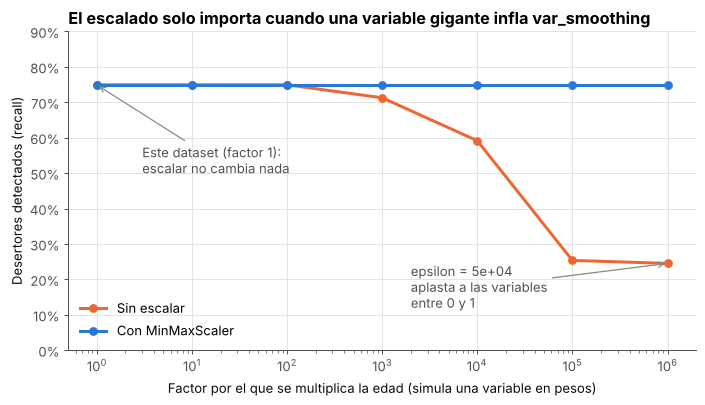

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(exp_escala["factor"], exp_escala["recall_sin_escalar"], "o-", color=NARANJA, lw=2.4, label="Sin escalar")
ax.plot(exp_escala["factor"], exp_escala["recall_con_minmax"], "o-", color=AZUL, lw=2.4, label="Con MinMaxScaler")
ax.set_xscale("log")
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, 0.9)
ax.set_xlabel("Factor por el que se multiplica la edad (simula una variable en pesos)")
ax.set_ylabel("Desertores detectados (recall)")
ax.set_title("El escalado solo importa cuando una variable gigante infla var_smoothing")
ult = exp_escala.iloc[-1]
ax.annotate(f"epsilon = {ult['epsilon']:.0e}\naplasta a las variables\nentre 0 y 1",
            xy=(ult["factor"], ult["recall_sin_escalar"]), xytext=(2e3, 0.12), color=TINTA2,
            arrowprops=dict(arrowstyle="->", color=GRIS))
ax.annotate("Este dataset (factor 1):\nescalar no cambia nada", xy=(1, 0.749), xytext=(3, 0.5), color=TINTA2,
            arrowprops=dict(arrowstyle="->", color=GRIS))
ax.legend(loc="lower left")
guardar("01_escalado_var_smoothing")

**Conclusión corregida:** en el ejemplo bancario, escalar ayudaba porque `Balance` inflaba `var_smoothing`, no por *underflow*. Aquí la varianza máxima es ~122 y el `epsilon` es ~1e-7: escalar es irrelevante. Ajustar `var_smoothing` o escalar son dos formas de resolver el mismo problema.

## 4. Error 2: ¿en qué momento se hace la predicción?
La v1 usaba las notas del **2º semestre**. Pero el resultado `Dropout` se registra al final de la duración normal de la carrera, y muchos estudiantes abandonan durante el primer año. Revisemos cuántos desertores ya no rindieron **ninguna evaluación** en cada semestre:

In [8]:
sin_eval = pd.DataFrame({
    "Desertores": [df.loc[y == 1, f"Curricular units {s} sem (evaluations)"].eq(0).mean() for s in ["1st", "2nd"]],
    "No desertores": [df.loc[y == 0, f"Curricular units {s} sem (evaluations)"].eq(0).mean() for s in ["1st", "2nd"]],
}, index=["1er semestre", "2º semestre"])
(sin_eval * 100).round(1).astype(str) + " %"

,Desertores,No desertores
1er semestre,17.3 %,3.4 %
2º semestre,20.9 %,3.5 %


El **21 % de los desertores** no rindió ninguna evaluación en el 2º semestre (vs. 3 % del resto): para cuando el modelo de la v1 tenía sus datos, **ya se habían ido**. Una alerta sobre ellos no sirve para retenerlos.

Entreno el mismo modelo en los **tres momentos** con validación cruzada estratificada repetida 5×5 (25 evaluaciones):

In [9]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
METRICAS = {"auc": "roc_auc", "recall": "recall", "precision": "precision", "accuracy": "accuracy"}

res_momentos = []
for momento, (cat, num) in MOMENTOS.items():
    r = cross_validate(GaussianNB(), df[cat + num], y, cv=cv, scoring=METRICAS)
    res_momentos.append({"Momento": momento, **{k: r[f"test_{k}"].mean() for k in METRICAS}})
res_momentos = pd.DataFrame(res_momentos).set_index("Momento")
res_momentos.round(3)

,auc,recall,precision,accuracy
Momento,,,,
Matrícula,0.692,0.485,0.507,0.683
Fin 1er semestre,0.846,0.688,0.687,0.799
Fin de año,0.874,0.728,0.747,0.833


In [10]:
cat, num = MOMENTOS["Fin de año"]
oof_fin = cross_val_predict(GaussianNB(), df[cat + num], y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
vp = (oof_fin == 1) & (y == 1)
ya_se_fue = df["Curricular units 2nd sem (evaluations)"].eq(0).values
pct_ya_se_fue = (vp & ya_se_fue).sum() / vp.sum()
print(f"Desertores bien detectados por el modelo de fin de año: {es(vp.sum())}")
print(f"De ellos, sin ninguna evaluación en el 2º semestre (ya se habían ido): "
      f"{es((vp & ya_se_fue).sum())} ({es(pct_ya_se_fue * 100, 0)} %)")

Desertores bien detectados por el modelo de fin de año: 1.036
De ellos, sin ninguna evaluación en el 2º semestre (ya se habían ido): 295 (28 %)


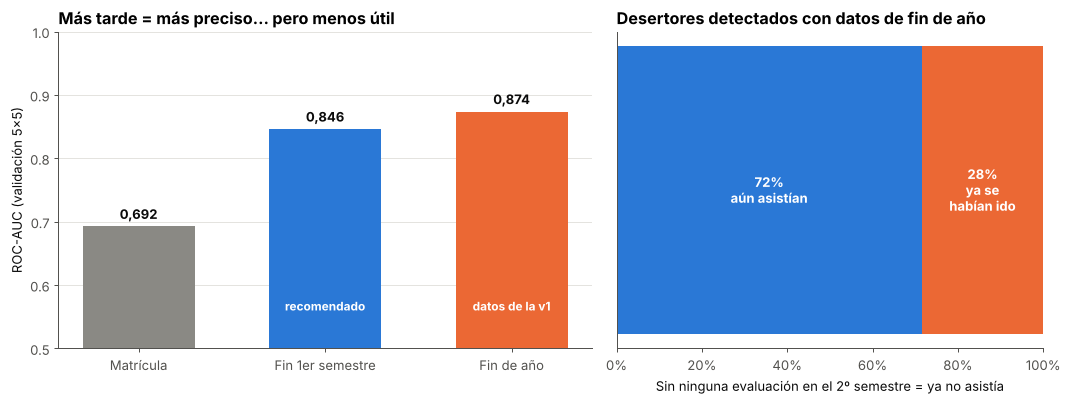

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
x = np.arange(len(res_momentos))
ax.bar(x, res_momentos["auc"], color=[GRIS, AZUL, NARANJA], width=0.6)
for i, v in enumerate(res_momentos["auc"]):
    ax.text(i, v + 0.012, es(v, 3), ha="center", fontweight="bold", color=TINTA)
ax.set_xticks(x, res_momentos.index); ax.set_ylim(0.5, 1); ax.set_ylabel("ROC-AUC (validación 5×5)")
ax.set_axisbelow(True); ax.grid(axis="x", visible=False)
ax.set_title("Más tarde = más preciso… pero menos útil")
ax.text(2, 0.56, "datos de la v1", ha="center", color="white", fontsize=9.5, fontweight="bold")
ax.text(1, 0.56, "recomendado", ha="center", color="white", fontsize=9.5, fontweight="bold")

ax = axes[1]
vals = [1 - pct_ya_se_fue, pct_ya_se_fue]
ax.barh([0], [vals[0]], color=AZUL, height=0.5)
ax.barh([0], [vals[1]], left=[vals[0]], color=NARANJA, height=0.5)
ax.text(vals[0] / 2, 0, f"{vals[0]:.0%}\naún asistían", ha="center", va="center", color="white", fontweight="bold")
ax.text(vals[0] + vals[1] / 2, 0, f"{vals[1]:.0%}\nya se\nhabían ido", ha="center", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 1); ax.set_yticks([]); ax.xaxis.set_major_formatter(PCT); ax.grid(False)
ax.set_title("Desertores detectados con datos de fin de año")
ax.set_xlabel("Sin ninguna evaluación en el 2º semestre = ya no asistía")
plt.tight_layout()
guardar("02_momento_prediccion")

**Lectura:** el modelo de fin de año luce mejor (ROC-AUC más alto), pero **casi 3 de cada 10** desertores que "detecta" ya habían dejado de asistir. El **fin del 1er semestre** es el mejor equilibrio: casi el mismo poder predictivo y tiempo para actuar durante el 2º semestre. A partir de aquí trabajo con ese momento.

## 5. Error 3: los supuestos de Naive Bayes
Naive Bayes asume que (a) cada variable tiene la distribución correcta y (b) las variables son **independientes** dentro de cada clase.

**(a) Códigos tratados como números.** Construyo un **Naive Bayes mixto**: `CategoricalNB` para las variables categóricas (cuenta frecuencias por categoría) y `GaussianNB` para las numéricas. Ambos se combinan sumando sus log-probabilidades, que es exactamente lo que dice el teorema de Bayes con independencia.

In [12]:
codigos = {c: {v: i for i, v in enumerate(sorted(df[c].unique()))} for c in NOMINALES + BINARIAS + FINANCIERAS}

class NaiveBayesMixto(ClassifierMixin, BaseEstimator):
    """CategoricalNB para columnas categóricas + GaussianNB para numéricas."""
    def __init__(self, cat=None, num=None, alpha=1.0):
        self.cat, self.num, self.alpha = cat, num, alpha
    def _cod(self, X):
        return np.column_stack([X[c].map(codigos[c]).values for c in self.cat])
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.cnb_ = CategoricalNB(alpha=self.alpha, min_categories=[len(codigos[c]) for c in self.cat]).fit(self._cod(X), y)
        self.gnb_ = GaussianNB().fit(X[self.num], y)
        return self
    def predict_proba(self, X):
        # log P(y) + Σ log P(x_cat|y) + Σ log P(x_num|y)  (el prior se cuenta una sola vez)
        j = (self.cnb_.predict_joint_log_proba(self._cod(X)) + self.gnb_.predict_joint_log_proba(X[self.num])
             - np.log(self.gnb_.class_prior_))
        j -= j.max(axis=1, keepdims=True)
        p = np.exp(j)
        return p / p.sum(axis=1, keepdims=True)
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

def logistica(cat, num):
    """Referencia: regresión logística con one-hot para códigos y estandarización para numéricas."""
    otras = [c for c in cat + num if c not in NOMINALES]
    prep = make_column_transformer((OneHotEncoder(handle_unknown="ignore"), NOMINALES), (StandardScaler(), otras))
    return make_pipeline(prep, LogisticRegression(max_iter=3000))

filas = []
for momento, (cat, num) in MOMENTOS.items():
    X = df[cat + num]
    for nombre, modelo in [("GaussianNB", GaussianNB()), ("Naive Bayes mixto", NaiveBayesMixto(cat, num)),
                           ("Regresión logística", logistica(cat, num))]:
        r = cross_validate(modelo, X, y, cv=cv, scoring=METRICAS)
        filas.append({"Momento": momento, "Modelo": nombre, **{k: r[f"test_{k}"].mean() for k in METRICAS}})
comparacion = pd.DataFrame(filas)
comparacion.to_csv(REP / "comparacion_modelos_momentos.csv", index=False)
comparacion.pivot(index="Modelo", columns="Momento", values="auc")[list(MOMENTOS)].round(3)

Momento,Matrícula,Fin 1er semestre,Fin de año
Modelo,,,
GaussianNB,0.692,0.846,0.874
Naive Bayes mixto,0.736,0.852,0.874
Regresión logística,0.767,0.902,0.920


**(b) Variables correlacionadas.** La tasa de aprobación del 1er y 2º semestre, o las notas de ambos semestres, están muy correlacionadas. Naive Bayes las cuenta como evidencia independiente: **cuenta dos veces la misma información** y sus probabilidades se vuelven extremas.

In [13]:
pares = [("Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"),
         ("tasa_aprobacion_1", "tasa_aprobacion_2")]
for a, b in pares:
    print(f"Correlación {a} ↔ {b}: {df[a].corr(df[b]):.2f}")

cat, num = MOMENTOS["Fin 1er semestre"]
X1 = df[cat + num]
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
prob = {n: cross_val_predict(m, X1, y, cv=skf, method="predict_proba")[:, 1]
        for n, m in [("GaussianNB", GaussianNB()), ("Naive Bayes mixto", NaiveBayesMixto(cat, num)),
                     ("Regresión logística", logistica(cat, num))]}
calib = pd.DataFrame({n: {"Brier (menor = mejor)": brier_score_loss(y, p),
                          "% probabilidades <1 % o >99 %": ((p < 0.01) | (p > 0.99)).mean() * 100,
                          "ROC-AUC": roc_auc_score(y, p)} for n, p in prob.items()}).T
calib.round(3)

Correlación Curricular units 1st sem (grade) ↔ Curricular units 2nd sem (grade): 0.84
Correlación tasa_aprobacion_1 ↔ tasa_aprobacion_2: 0.87


,Brier (menor = mejor),% probabilidades <1 % o >99 %,ROC-AUC
GaussianNB,0.182,75.972,0.845
Naive Bayes mixto,0.168,65.484,0.851
Regresión logística,0.104,5.945,0.902


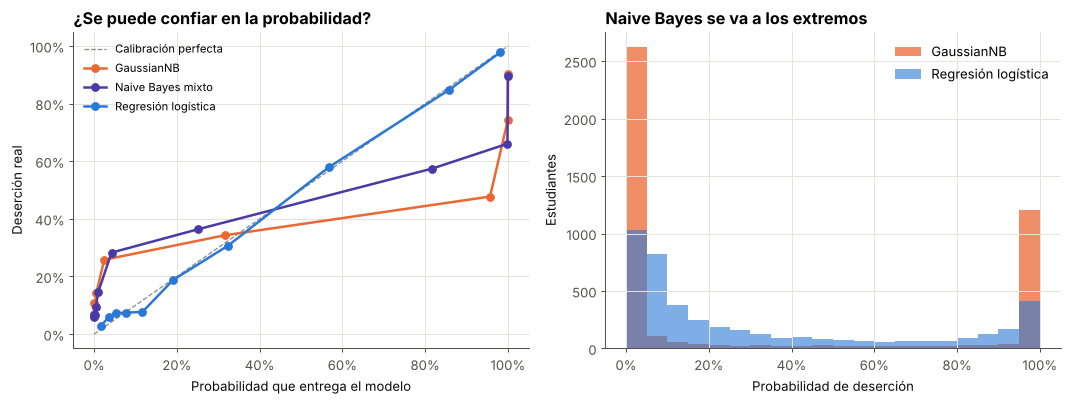

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
ax.plot([0, 1], [0, 1], "--", color=GRIS, lw=1, label="Calibración perfecta")
for (n, p), c in zip(prob.items(), [NARANJA, VIOLETA, AZUL]):
    fr, mp = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(mp, fr, "o-", color=c, lw=2, label=n)
ax.xaxis.set_major_formatter(PCT); ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Probabilidad que entrega el modelo"); ax.set_ylabel("Deserción real")
ax.set_title("¿Se puede confiar en la probabilidad?"); ax.legend(loc="upper left", fontsize=9)

ax = axes[1]
bins = np.linspace(0, 1, 21)
ax.hist(prob["GaussianNB"], bins=bins, color=NARANJA, alpha=0.75, label="GaussianNB")
ax.hist(prob["Regresión logística"], bins=bins, color=AZUL, alpha=0.6, label="Regresión logística")
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("Probabilidad de deserción"); ax.set_ylabel("Estudiantes")
ax.set_title("Naive Bayes se va a los extremos"); ax.legend()
plt.tight_layout()
guardar("03_supuestos_calibracion")

**Lectura:**
- El **Naive Bayes mixto** mejora sobre todo en la matrícula, donde casi toda la información está en códigos (carrera, modo de postulación, ocupación de los padres). Tratar bien las variables importa justamente cuando hay pocas señales.
- **GaussianNB entrega probabilidades extremas**: 3 de cada 4 quedan bajo 1 % o sobre 99 % (la logística: 6 %). Sirve para **ordenar** estudiantes, pero su "99 %" no significa 99 %.
- La **regresión logística** gana en todos los momentos y está bien calibrada: maneja la correlación entre variables en vez de sumarla dos veces.

Naive Bayes sigue siendo un buen punto de partida (rápido, sin ajuste de parámetros), pero para este caso **recomiendo la regresión logística**.

## 6. Validación honesta: un split vs. 25
La v1 evaluó con un solo split. ¿Qué tan representativo fue ese 84,8 %?

In [15]:
r_v1 = cross_validate(GaussianNB(), X_v1, y, cv=cv, scoring={"accuracy": "accuracy"})
acc = r_v1["test_accuracy"]
print(f"Mismo modelo y variables de la v1 en 25 particiones:")
print(f"  Exactitud media {es(acc.mean() * 100, 1)} %  |  mínimo {es(acc.min() * 100, 1)} %  |  máximo {es(acc.max() * 100, 1)} %")
print(f"  El split de la v1 (84,8 %) supera al {np.mean(acc < v1['Exactitud (accuracy)']):.0%} de las particiones")

Mismo modelo y variables de la v1 en 25 particiones:
  Exactitud media 83,3 %  |  mínimo 81,1 %  |  máximo 85,6 %
  El split de la v1 (84,8 %) supera al 92% de las particiones


El 84,8 % de la v1 fue un split **afortunado**: superó a casi todas las particiones. La exactitud esperada de ese modelo es ~83 %. Con 4.424 estudiantes la variación es moderada, pero reportar un solo número sin su rango exagera la certeza.

## 7. Alerta temprana: ¿a cuántos contactar? (PACE · Ejecutar)
Lo que el equipo de retención necesita no es una exactitud, sino una **lista priorizada**. Con el modelo de fin del 1er semestre, si el equipo puede contactar a una fracción de estudiantes, ¿cuántos desertores alcanza?

Comparo con una **regla simple** que cualquier coordinación podría aplicar sin modelo: priorizar por menor tasa de aprobación del 1er semestre (y, en empate, menor nota).

In [16]:
orden_regla = np.lexsort((df["Curricular units 1st sem (grade)"].values, df["tasa_aprobacion_1"].values))
puntaje_regla = np.empty(len(df)); puntaje_regla[orden_regla] = np.arange(len(df))[::-1]

def alcance(puntaje, fraccion):
    k = int(round(fraccion * len(puntaje)))
    top = np.argsort(-puntaje, kind="stable")[:k]
    return y[top].sum() / y.sum(), y[top].mean()

capacidades = np.linspace(0.05, 0.6, 12)
curvas = {"Regla simple (tasa de aprobación)": puntaje_regla,
          "GaussianNB": prob["GaussianNB"],
          "Regresión logística": prob["Regresión logística"]}
filas = []
for cap in [0.20, 0.30]:
    for n, p in curvas.items():
        rec, prec = alcance(p, cap)
        filas.append({"Capacidad": f"{cap:.0%} de los estudiantes", "Método": n,
                      "Desertores alcanzados": rec, "Precisión de la lista": prec})
alerta = pd.DataFrame(filas)
alerta.to_csv(REP / "alerta_temprana.csv", index=False)
alerta.round(3)

,Capacidad,Método,Desertores alcanzados,Precisión de la lista
0,20% de los estudiantes,Regla simple (tasa de aprobación),0.490,0.788
1,20% de los estudiantes,GaussianNB,0.513,0.824
2,20% de los estudiantes,Regresión logística,0.569,0.913
3,30% de los estudiantes,Regla simple (tasa de aprobación),0.669,0.716
4,30% de los estudiantes,GaussianNB,0.662,0.708
5,30% de los estudiantes,Regresión logística,0.749,0.802


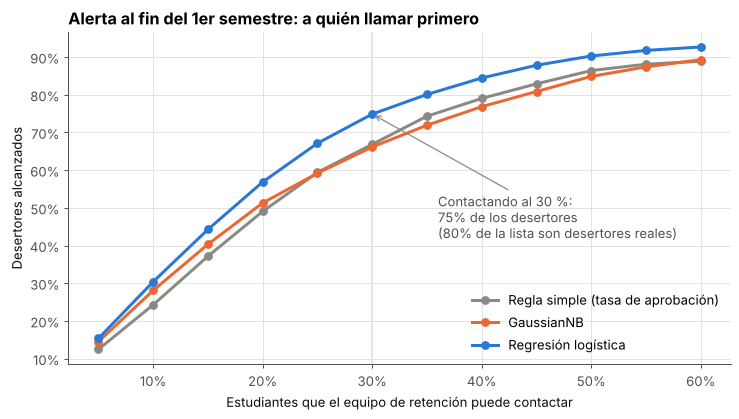

In [17]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for (n, p), c in zip(curvas.items(), [GRIS, NARANJA, AZUL]):
    ax.plot(capacidades, [alcance(p, f)[0] for f in capacidades], "o-", color=c, lw=2.4, label=n)
ax.axvline(0.30, color=GRILLA, lw=1.5, zorder=0)
r30 = alcance(prob["Regresión logística"], 0.30)
ax.annotate(f"Contactando al 30 %:\n{r30[0]:.0%} de los desertores\n({r30[1]:.0%} de la lista son desertores reales)",
            xy=(0.30, r30[0]), xytext=(0.36, 0.42), color=TINTA2, arrowprops=dict(arrowstyle="->", color=GRIS))
ax.xaxis.set_major_formatter(PCT); ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Estudiantes que el equipo de retención puede contactar")
ax.set_ylabel("Desertores alcanzados")
ax.set_title("Alerta al fin del 1er semestre: a quién llamar primero")
ax.legend(loc="lower right")
guardar("04_alerta_temprana")

## 8. Antes y después

In [18]:
log1 = comparacion.query("Momento == 'Fin 1er semestre' and Modelo == 'Regresión logística'").iloc[0]
resumen = pd.DataFrame({
    "Versión 1": ["GaussianNB", "Fin de año (2º semestre)", "1 split", f"{es(v1['Exactitud (accuracy)'] * 100, 1)} %",
                  "No reportado", "Underflow (incorrecto)", "No evaluada"],
    "Versión 2": ["Regresión logística (NB mixto como alternativa)", "Fin del 1er semestre", "25 particiones (5×5)",
                  f"{es(log1['accuracy'] * 100, 1)} %", es(log1["auc"], 3), "var_smoothing (demostrado)",
                  f"Brier {es(calib.loc['Regresión logística', 'Brier (menor = mejor)'], 3)}"],
}, index=["Modelo", "Momento de la predicción", "Validación", "Exactitud", "ROC-AUC",
          "Explicación del escalado", "Calibración"])
resumen.to_csv(REP / "antes_despues.csv")
resumen

,Versión 1,Versión 2
Modelo,GaussianNB,Regresión logística (NB mixto como alternativa)
Momento de la predicción,Fin de año (2º semestre),Fin del 1er semestre
Validación,1 split,25 particiones (5×5)
Exactitud,"84,8 %","86,0 %"
ROC-AUC,No reportado,"0,902"
Explicación del escalado,Underflow (incorrecto),var_smoothing (demostrado)
Calibración,No evaluada,"Brier 0,104"


## 9. Conclusiones (PACE · Construir y Ejecutar)

1. **El escalado no era el problema.** GaussianNB es inmune a escalar cada variable; lo único que lo afecta es `var_smoothing`, que crece con la varianza más grande. Diagnosticar el mecanismo vale más que aplicar la receta.
2. **El momento importa tanto como el modelo.** Con datos de fin de año el modelo se ve mejor, pero casi 3 de cada 10 desertores detectados ya se habían ido. Una alerta al **fin del 1er semestre** deja un semestre completo para actuar y, con regresión logística, logra **86 % de exactitud y ROC-AUC 0,90**: antes y mejor que la v1.
3. **Revisar los supuestos cambia la recomendación.** Tratar los códigos como categorías mejora a Naive Bayes, sobre todo en la matrícula. Aun así, la correlación entre variables hace que sus probabilidades sean extremas; la **regresión logística** gana en todos los momentos y entrega probabilidades confiables.
4. **Aplicación:** si el equipo de retención puede contactar al 30 % de los estudiantes al terminar el 1er semestre, la lista de la regresión logística alcanza a **3 de cada 4 futuros desertores** (75 %), y 8 de cada 10 contactados son desertores reales. La regla simple basada en la tasa de aprobación alcanza 67 %.

**Limitaciones:** datos de una sola institución portuguesa; el resultado `Dropout` no trae la fecha exacta del abandono (por eso uso "cero evaluaciones" como señal de que el estudiante ya no asistía); y el modelo identifica riesgo, no causas: las intervenciones deberían evaluarse con un piloto.

**Lección personal:** volver a un proyecto propio con ojos nuevos fue más valioso que empezar uno desde cero.